# 03 · Data quality - and cleaning without cheating

**Goal:** see what messy data look like, build the cleaning rule ourselves, and measure how much it matters.

The golden rule of this notebook: **a cleaning step must only use information available at the time.** A rule that peeks at later weeks
("this value was wrong because next week's looks normal") is leakage in disguise.

In [1]:
from tutorial_utils import *
style()
panels = {s: load_panel(s) for s in ["clean", "realistic", "stressed"]}
ind = ["market_arrivals_tonnes", "estimated_demand_index", "rainfall_mm", "temperature_c", "drought_index", "fuel_cost_index", "transport_cost_kes_tonne", "regional_supply_index"]
summary = pd.DataFrame({sc: {
    "price missing %": p.wholesale_price_kes_kg.isna().mean() * 100,
    "labelled reporting errors %": (p.data_quality_flag == "suspect").mean() * 100,
    "mean indicator missing %": p[ind].isna().mean().mean() * 100,
    "late-delivered rows %": p.report_delay_weeks.mean() * 100,
    "rows inside a real event %": p.event_affected.mean() * 100} for sc, p in panels.items()}).T
summary.round(2)

,price missing %,labelled reporting errors %,mean indicator missing %,late-delivered rows %,rows inside a real event %
clean,0.00,0.00,0.00,0.00,31.7
realistic,3.72,0.74,7.09,11.86,31.7
stressed,6.54,0.90,12.11,35.19,31.7


Three scenarios share **one** underlying world and differ only in the data-quality layer: *clean* (nothing wrong), *realistic* (a few gaps, a few errors),
*stressed* (long gaps, market-wide outages, more errors and late data).

## What the problems look like
**Missing prices** - note they are not evenly spread: some markets report worse, and the stressed scenario has two market-wide outages.

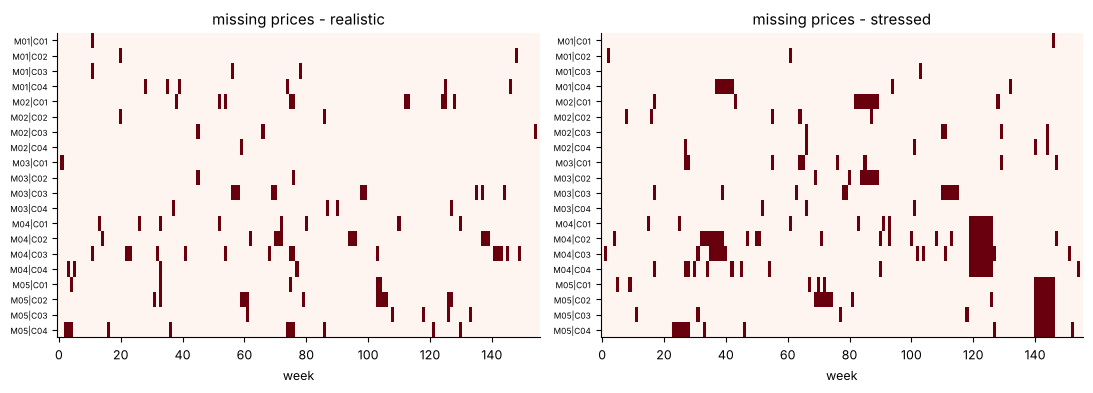

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, sc in zip(axes, ["realistic", "stressed"]):
    m = wide(panels[sc], "wholesale_price_kes_kg").isna().T
    ax.imshow(m.values, aspect="auto", cmap="Reds", interpolation="nearest"); ax.grid(False)
    ax.set_yticks(range(len(m))); ax.set_yticklabels([i.replace("MKT-", "M").replace("CRP-", "C") for i in m.index], fontsize=6)
    ax.set_title(f"missing prices - {sc}"); ax.set_xlabel("week")
plt.tight_layout()

**Reporting errors** - a decimal slip (×10, ×0.1), a transposition (×2.5, ×0.4) or an impossible zero. We know exactly which rows were corrupted
(`data_quality_flag == "suspect"`) *because we injected them*. A real forecaster would not.

In [3]:
rl = panels["realistic"]
sus = rl[rl.data_quality_flag == "suspect"].copy()
sus["ratio_to_true"] = sus.wholesale_price_kes_kg / sus.latent_price_kes_kg
print(len(sus), "injected errors in the realistic scenario; ratio of reported to true price:")
print(sus.ratio_to_true.round(2).value_counts().sort_index().to_string())

23 injected errors in the realistic scenario; ratio of reported to true price:
ratio_to_true
0.00     1
0.10     4
0.39     1
0.40     3
0.41     1
2.41     1
2.46     1
2.49     1
2.50     2
2.53     1
9.67     1
9.85     2
9.89     2
10.11    1
10.29    1


## Build a causal outlier filter
**Rule:** keep a reported price unless it is impossible (≤ 0) or it differs from the median of the last 5 *accepted* prices by more than `thr` (in log terms, 0.70 ≈ a factor of 2).

**Complication:** a *genuine* level shift (a real shock) would also exceed the threshold, and we must not erase real market behaviour. Using only the past, we cannot know
whether a sudden jump is an error or the start of a new level - but we **can** notice that the *next* report agrees with it. So: if the value agrees (within 15%) with the previous
week's report, accept it. A one-off spike is rejected; a lasting shift is accepted from the second week on.

rejected weeks: [10]


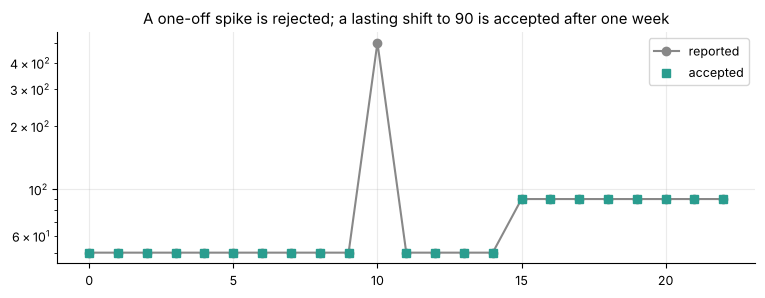

In [4]:
def causal_filter(x, thr=0.70, ref_window=5, agree_tol=0.15):
    x = np.asarray(x, float)
    accepted = np.full(len(x), np.nan)
    rejected = np.zeros(len(x), dtype=bool)
    history, prev_raw = [], np.nan
    for t, v in enumerate(x):
        if np.isnan(v):                         # missing: nothing to judge
            prev_raw = np.nan
            continue
        ok = True
        if v <= 0:                              # impossible value
            ok = False
        elif len(history) >= 3:                 # need a few accepted values to build a reference
            ref = np.median(history[-ref_window:])
            if abs(np.log(v / ref)) > thr:      # far from recent prices ...
                agrees_with_last_week = (not np.isnan(prev_raw)) and prev_raw > 0 and abs(np.log(v / prev_raw)) < agree_tol
                ok = agrees_with_last_week      # ... accept only if last week said the same
        if ok:
            accepted[t] = v; history.append(v)
        else:
            rejected[t] = True
        prev_raw = v
    return accepted, rejected

# a spike versus a genuine level shift
demo = np.r_[np.full(10, 50.0), 500.0, np.full(4, 50.0), np.full(8, 90.0)]
acc, rej = causal_filter(demo)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(demo, "o-", color="#888", label="reported"); ax.plot(acc, "s", color="#2a9d8f", label="accepted"); ax.set_yscale("log"); ax.legend()
ax.set_title("A one-off spike is rejected; a lasting shift to 90 is accepted after one week")
print("rejected weeks:", np.where(rej)[0])

## How good is it? (we can check - because the audit labels exist)
We apply the filter to every series in the realistic scenario and compare with the injected-error labels. **The labels are used only to grade the filter, never as an input to it.**

In [5]:
raw = wide(rl, "wholesale_price_kes_kg")
acc_rows, rej_rows = {}, {}
for c in raw.columns:
    acc_rows[c], rej_rows[c] = causal_filter(raw[c].values)
accepted, rejected = pd.DataFrame(acc_rows, index=raw.index), pd.DataFrame(rej_rows, index=raw.index)
truth = wide(rl, "data_quality_flag").eq("suspect")
tp = int((rejected & truth).sum().sum()); fp = int((rejected & ~truth).sum().sum()); fn = int((~rejected & truth).sum().sum())
print(f"true errors caught: {tp}   false alarms: {fp}   missed: {fn}")
print(f"precision {tp/(tp+fp):.2f}  recall {tp/(tp+fn):.2f}")
latent = wide(rl, "latent_price_kes_kg")
for kind, mask in [("FALSE ALARM", rejected & ~truth), ("MISSED", truth & ~rejected)]:
    for c in mask.columns:
        for w in mask.index[mask[c]]:
            print(f"{kind}: {c} week {w}: reported {raw.loc[w, c]}, true {latent.loc[w, c]:.1f}; reported prices around it: {raw[c].loc[max(1, w-6):w+2].round(1).tolist()}")

true errors caught: 22   false alarms: 1   missed: 1
precision 0.96  recall 0.96
FALSE ALARM: MKT-03|CRP-02 week 71: reported 39.36, true 39.9; reported prices around it: [106.0, 104.3, 94.0, 81.4, 66.9, 47.7, 39.4, 37.7, 42.6]
MISSED: MKT-04|CRP-03 week 3: reported 136.32, true 53.9; reported prices around it: [50.9, 51.8, 136.3, 51.2, 51.1]


It catches almost all the gross errors, but look at the two mistakes - they are the two classic failure modes of any outlier rule:

* **A false alarm on a real shock.** Eldoret tomatoes, week 71: the price genuinely crashed from about 106 to 39 KES/kg in seven weeks during a harvest glut (event EV02).
  The reported 39.4 was far below the recent median *and* more than 15% below the previous week's 47.7, so the rule briefly distrusted it. Only that one week is lost - the next week
  is accepted - but it shows the trade-off: a rule strict enough to catch ×0.4 errors will sometimes doubt a very fast real move.
* **A miss from a cold start.** Kisumu potatoes, week 3: the filter needs at least three accepted prices to build a reference, and only two existed, so a ×2.5 error got through.

And no rule can catch an error that *looks plausible* - a value 10% too high is invisible. **Subtle reporting errors would survive.**

## Why "causal" matters - a test you can run
A filter is causal if its output at week `t` is unchanged when all later weeks are deleted. Let us verify on a real series.

In [6]:
x = raw["MKT-04|CRP-03"].values
full, _ = causal_filter(x); part, _ = causal_filter(x[:60])
print("first 60 outputs identical when the future is removed:", np.array_equal(np.nan_to_num(full[:60]), np.nan_to_num(part)))

# a NON-causal alternative: flag a point if it is >0.3 (log) away from the CENTRED rolling median - this looks at the next weeks
shift_series = np.r_[np.full(10, 50.0), np.full(10, 90.0)]            # a genuine level shift starting at index 10
def centred_flags(v):
    med = pd.Series(v).rolling(5, center=True, min_periods=1).median().values
    return np.abs(np.log(v / med)) > 0.3
print("index 10 = first week at the new level")
print("centred rule, full data      -> flagged:", bool(centred_flags(shift_series)[10]))
print("centred rule, future removed -> flagged:", bool(centred_flags(shift_series[:11])[10]), "  (decision changed: the rule used the future)")
print("causal filter, full data     -> rejected:", bool(causal_filter(shift_series, thr=0.5)[1][10]))
print("causal filter, future removed-> rejected:", bool(causal_filter(shift_series[:11], thr=0.5)[1][10]), "  (same decision)")

first 60 outputs identical when the future is removed: True
index 10 = first week at the new level
centred rule, full data      -> flagged: False
centred rule, future removed -> flagged: True   (decision changed: the rule used the future)
causal filter, full data     -> rejected: True
causal filter, future removed-> rejected: True   (same decision)


The centred rule changes its verdict about week 10 depending on whether weeks 11-12 exist: it "knows" the new level persists. In real time you would not know that.
The causal filter passes the future-removal test **by construction**. Notebook 05 turns this idea into the project's main leakage test.

## Carrying forward and staleness
After rejecting errors, gaps remain. The simplest repair that uses only the past is **last observation carried forward (LOCF)** - but not forever: after a cap (8 weeks)
the value is declared unknown. We also keep track of the **age** of the latest price, because a 3-week-old "latest price" is a worse reference than a fresh one.

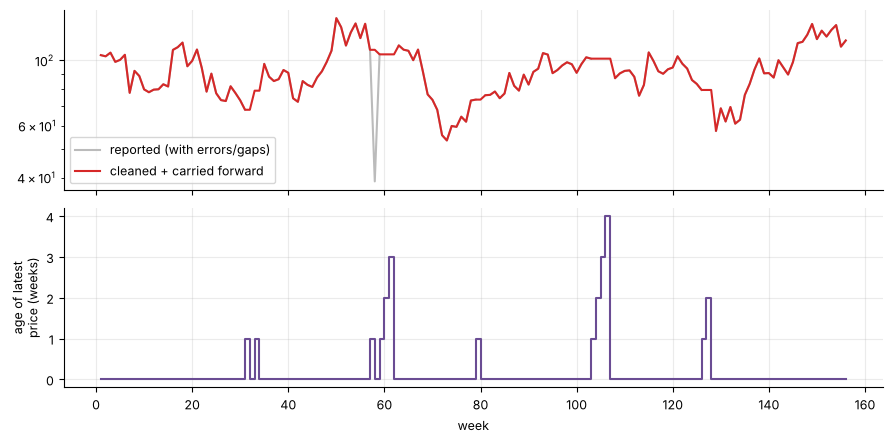

In [7]:
s = accepted["MKT-05|CRP-02"]
filled = s.ffill(limit=8)
age = s.notna().cumsum()
age = s.index.to_series().groupby(age).transform(lambda w: w - w.min()).where(filled.notna())
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 4.5))
axes[0].plot(raw["MKT-05|CRP-02"], color="#bbb", label="reported (with errors/gaps)"); axes[0].plot(filled, color="#d62828", label="cleaned + carried forward"); axes[0].legend(); axes[0].set_yscale("log")
axes[1].step(age.index, age.values, color="#6a4c93"); axes[1].set_ylabel("age of latest\nprice (weeks)"); axes[1].set_xlabel("week")
plt.tight_layout()

## How much does cleaning matter?
We score the **naive forecast** two ways: using the raw latest reported price (errors included) and using the cleaned latest price. Both are scored on the same target rows
(the targets that are injected errors are excluded from scoring, as in the pipeline). Test window only: origins 131 … 156 − h.

In [8]:
def naive_mae(panel_df, handling, lo=VAL_END + 1):
    r = wide(panel_df, "wholesale_price_kes_kg")
    if handling:
        a = pd.DataFrame({c: causal_filter(r[c].values)[0] for c in r.columns}, index=r.index)
        ref = a.ffill(limit=8)
    else:
        ref = r.ffill()
    ref_clean = pd.DataFrame({c: causal_filter(r[c].values)[0] for c in r.columns}, index=r.index).ffill(limit=8)   # common rows for both modes
    suspect = wide(panel_df, "data_quality_flag").eq("suspect")
    out = {}
    for h in HORIZONS:
        origins = np.arange(lo, eval_hi(h, TEST_END) + 1)
        tgt = r.shift(-h).loc[origins]; ok = tgt.notna() & ~suspect.shift(-h, fill_value=False).loc[origins] & ref_clean.loc[origins].notna()
        out[h] = ((tgt - ref.loc[origins]).abs().where(ok)).stack().mean()
    return np.mean(list(out.values()))

rows = []
for sc in ["clean", "realistic", "stressed"]:
    rows.append(dict(scenario=sc, raw=naive_mae(panels[sc], False), cleaned=naive_mae(panels[sc], True)))
tab = pd.DataFrame(rows).set_index("scenario"); tab["raw is worse by %"] = (tab.raw / tab.cleaned - 1) * 100
print("Naive forecast, test MAE (KES/kg), mean over horizons 1, 2, 4:")
tab.round(2)

Naive forecast, test MAE (KES/kg), mean over horizons 1, 2, 4:


,raw,cleaned,raw is worse by %
scenario,,,
clean,5.81,5.81,0.00
realistic,10.32,6.16,67.45
stressed,9.65,6.74,43.14


Compare with the pipeline's own numbers for the naive forecast (`results/scenario_comparison_test.csv`):

In [9]:
sc_ref = pd.read_csv(RESULTS / "scenario_comparison_test.csv")
print(sc_ref[sc_ref.variant == "Naive"][["combo", "mean_over_horizons"]].round(2).to_string(index=False))

            combo  mean_over_horizons
    clean|handled                5.81
realistic|handled                6.16
    realistic|raw               10.32
 stressed|handled                6.74
     stressed|raw                9.65


Our numbers land very close to the pipeline's (differences come from tiny details in which rows count as evaluable).

**What to take away**
* With cleaning, error grows only modestly from clean → realistic → stressed.
* Without it, a single ×10 price becomes the "latest price" and spoils every forecast that uses it as a reference - roughly +30-90% error. **Data quality can matter more than model choice.**
* (The raw ordering of "realistic" vs "stressed" depends on *where* the random errors happened to fall - one realisation of the world. Don't over-interpret it.)

## Exercises
1. Lower `thr` from 0.70 to 0.30 and recompute precision/recall. What happens to false alarms? (Look at which genuine shocks get flagged - for example Eldoret tomatoes around week 71 - and how many errors you now catch.)
2. Raise `agree_tol` to 0.5. Does a one-off spike now survive? Why is the agreement rule a double-edged sword?
3. The cold-start miss (Kisumu potatoes, week 3) happens because the filter waits for 3 accepted prices. Change that number to 2 or to 1 - what do you gain, and what do you risk?
4. Change the LOCF cap from 8 weeks to 2 and recompute the cleaned naive MAE in the stressed scenario (which has 8-week outages). Which is better - a stale price or no price?
5. Run the causality check on three more real series. Then invent another series where the centred rule changes its verdict when the future is removed.

**Where this lives in the pipeline:** `src/agriprice/cleaning.py` (`causal_outlier_filter`, `locf`), applied in `src/agriprice/features.py`; the quality layer itself in `src/agriprice/degrade.py`.